# Proyecto final 
![logo Itq](img/ITQ.png)

**Nombre:** Freddy Guevara, Edgar Ulloa, Edgar Crespo

**Fecha** *25-11-2026*

**Link Repositorio** https://github.com/Fguevara92/Fund_Machin_Learn_IA_Noct_26_27/blob/main/Programa13_Variables_Cuantitativa.ipynb

In [1]:
#Importacion de librerias
import pandas as pd
import numpy as np
from sklearn.datasets import load_iris
import zipfile
import seaborn as sns
import matplotlib.pyplot as plt
import os
from sklearn import preprocessing

### Configuración del entorno de descarga

Le indico a Python en qué carpeta está mi archivo **kaggle.json**, que tiene mis credenciales para descargar datos desde Kaggle.

In [2]:
# Configuramos el entorno de descarga
os.environ['KAGGLE_CONFIG_DIR'] = "C:/Users/fguev/.kaggle"

### Carpeta dataset

Crea la carpeta dataset. Si ya existe, no pasa nada y no da error.

In [3]:
#Creamos la carpeta dataset
os.makedirs("dataset", exist_ok=True)

### Descarga del dataset

Descarga el dataset **E-Commerce Data (Online Retail)** desde Kaggle. Si aparece el mensaje *Skipping*, significa que ya lo teníamos descargado y por eso no lo volvió a bajar.

In [6]:
#Descargamos el dataset
!kaggle datasets download -d carrie1/ecommerce-data

Dataset URL: https://www.kaggle.com/datasets/carrie1/ecommerce-data
License(s): unknown
ecommerce-data.zip: Skipping, found more recently modified local copy (use --force to force download)


### Descompresión del dataset

Abrimos el zip en modo lectura. El **with** lo cierra solo al terminar.

**zip_ref.extractall("dataset"):** saca todo el contenido del zip y lo guarda en la carpeta dataset.

In [14]:
# Descomprimimos el archivo
with zipfile.ZipFile("ecommerce-data.zip", 'r') as zip_ref:
    zip_ref.extractall("dataset")

# Verificamos qué archivo quedó dentro de la carpeta
print(os.listdir("dataset"))

['.ipynb_checkpoints', 'data.csv', 'database.sqlite', 'Iris.csv', 'outliers.csv']


### Carga del dataset

Leemos el archivo CSV y lo guardamos en el data frame. Usamos **encoding="ISO-8859-1"** porque el archivo tiene caracteres especiales (como el símbolo £) que no se leen con la codificación normal UTF-8.

In [8]:
# Cargamos el conjunto de datos
df_original = pd.read_csv("dataset/data.csv", encoding="ISO-8859-1")

### Copia de trabajo

Creo una copia del dataset original. Todas las limpiezas las hago sobre **df**, y **df_original** se queda intacto para comparar el antes y el después en la fase de Evaluación.

In [10]:
# Copia de trabajo: el original no se modifica
df = df_original.copy()

### Vista previa

Muestro las primeras filas y el tamaño del dataset (filas, columnas) para tener una primera idea de cómo vienen los datos.

In [13]:
# Tamaño del dataset y primeras filas
print("Filas y columnas:", df.shape)
df.head()

Filas y columnas: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


## FASE 2: COMPRENSIÓN DE LOS DATOS

### Estructura general del dataset

Reviso cuántas filas y columnas tiene el dataset, el tipo de dato de cada columna y cuántos valores no nulos hay.

- **Dtype:** tipo de dato que pandas le asignó a cada columna.
- **Non-Null Count:** cuántos valores tienen dato (no están vacíos).

In [16]:
# Información general: columnas, tipos de datos y valores no nulos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


**Interpretación:**
- El dataset tiene **541,909 filas y 8 columnas**
- Hay dos columnas con valores faltantes: **Description** (540,455 de 541,909, le faltan 1,454) y **CustomerID** (406,829 de 541,909, le faltan 135,080).
- **InvoiceDate** está como `object` (texto), cuando debería ser `datetime`. Así no puedo extraer meses, días ni calcular hace cuánto compró un cliente.
- **CustomerID** aparece como `float64` (decimal), pero es un código de cliente. Esto pasa porque pandas usa `NaN` para los vacíos, y `NaN` solo existe en columnas decimales.
- **InvoiceNo** y **StockCode** son `object` porque algunos valores tienen letras (por ejemplo, la "C" de las cancelaciones o códigos como 85123A).

### Diccionario de variables

Describo el significado de cada variable según la fuente original (UCI Machine Learning Repository) y el tipo de dato que tiene.

In [17]:
# Diccionario de variables
diccionario = pd.DataFrame({
    "Variable": ["InvoiceNo", "StockCode", "Description", "Quantity",
                 "InvoiceDate", "UnitPrice", "CustomerID", "Country"],
    "Descripción": [
        "Número de factura de 6 dígitos. Si empieza con 'C' es una cancelación",
        "Código único del producto",
        "Nombre del producto",
        "Cantidad de unidades del producto en esa factura",
        "Fecha y hora en que se generó la factura",
        "Precio por unidad en libras esterlinas (£)",
        "Código único del cliente (5 dígitos)",
        "País donde reside el cliente"
    ],
    "Tipo de variable": ["Categórica (ID)", "Categórica (ID)", "Categórica (texto)",
                         "Numérica discreta", "Fecha", "Numérica continua",
                         "Categórica (ID)", "Categórica nominal"],
    "Tipo en pandas": df.dtypes.astype(str).values
})

diccionario

,Variable,Descripción,Tipo de variable,Tipo en pandas
0,InvoiceNo,Número de factura de 6 dígitos. Si empieza con...,Categórica (ID),object
1,StockCode,Código único del producto,Categórica (ID),object
2,Description,Nombre del producto,Categórica (texto),object
3,Quantity,Cantidad de unidades del producto en esa factura,Numérica discreta,int64
4,InvoiceDate,Fecha y hora en que se generó la factura,Fecha,object
5,UnitPrice,Precio por unidad en libras esterlinas (£),Numérica continua,float64
6,CustomerID,Código único del cliente (5 dígitos),Categórica (ID),float64
7,Country,País donde reside el cliente,Categórica nominal,object


**Interpretación:**
- De las 8 variables, solo **Quantity** y **UnitPrice** son realmente numéricas. Las demás son categóricas o de fecha.
- Hay diferencias entre el tipo real de la variable y el tipo que asignó pandas: **CustomerID** es categórica pero está como `float64`, e **InvoiceDate** es una fecha pero está como `object`.
- Estas diferencias las corregiré en la fase de Preparación de los datos.

### Valores únicos por variable

Cuento cuántos valores distintos tiene cada columna para saber cuántas facturas, productos, clientes y países hay.

In [18]:
# Cantidad de valores distintos por columna
df.nunique()

InvoiceNo      25900
StockCode       4070
Description     4223
Quantity         722
InvoiceDate    23260
UnitPrice       1630
CustomerID      4372
Country           38
dtype: int64

**Interpretación:**
- Hay **25,900 facturas**, **4,070 productos**, **4,372 clientes** identificados y **38 países**.
- Las 541,909 filas no son 541,909 ventas: en promedio, cada factura tiene unas 21 líneas de productos (541,909 / 25,900).
- **Description (4,223) tiene más valores que StockCode (4,070)**. Si cada producto tuviera una sola descripción, deberían ser iguales, así que algunos códigos tienen más de una descripción. Puede deberse a cambios de nombre, errores de escritura o notas manuales. Lo revisaré en el diagnóstico.
- **InvoiceDate (23,260) tiene menos valores que InvoiceNo (25,900)** porque la fecha llega solo hasta el minuto, y en algunos casos se generaron varias facturas en el mismo minuto.

### Estadística descriptiva de variables numéricas

Calculo las medidas principales de Quantity y UnitPrice: promedio, desviación estándar, mínimo, cuartiles y máximo.

In [19]:
# Estadísticas de las variables numéricas
df[["Quantity", "UnitPrice"]].describe()

,Quantity,UnitPrice
count,541909.000000,541909.000000
mean,9.552250,4.611114
std,218.081158,96.759853
min,-80995.000000,-11062.060000
25%,1.000000,1.250000
50%,3.000000,2.080000
75%,10.000000,4.130000
max,80995.000000,38970.000000


**Interpretación:**

**Quantity:**
- La mediana es **3 unidades** y el 75 % de los registros tiene **10 unidades o menos**, así que la mayoría son compras pequeñas.
- El mínimo es **-80,995** y el máximo **80,995**. Una cantidad negativa no es una venta: probablemente corresponde a devoluciones o cancelaciones (facturas que empiezan con "C"). Que el mínimo y el máximo sean el mismo número sugiere que una compra muy grande fue cancelada después.
- La desviación estándar (218) es muy grande comparada con la media (9.55), lo que indica valores extremos.

**UnitPrice:**
- La mediana es **£2.08**, así que la mayoría de productos son baratos.
- El mínimo es **-£11,062.06**. Un precio negativo no tiene sentido para un producto, por lo que podría ser un ajuste contable. Lo verificaré en el diagnóstico.
- El máximo es **£38,970**, muy lejos del 75 % (£4.13). Debo revisar si es un producto real o un registro especial.

**En ambas variables la media es mayor que la mediana**, lo que indica una distribución sesgada a la derecha: hay pocos valores muy grandes que jalan el promedio hacia arriba.

### Distribución de ventas por país

Cuento cuántas filas (líneas de venta) hay por país para ver de dónde vienen los clientes.

In [20]:
# Top 10 países con más registros
df["Country"].value_counts().head(10)

Country
United Kingdom    495478
Germany             9495
France              8557
EIRE                8196
Spain               2533
Netherlands         2371
Belgium             2069
Switzerland         2002
Portugal            1519
Australia           1259
Name: count, dtype: int64

**Interpretación:**
- **United Kingdom** concentra **495,478 registros (91.4 %)**. Es lógico, porque es una empresa británica.
- Le siguen Germany (1.8 %), France (1.6 %) y EIRE (1.5 %). **EIRE** es el nombre de Irlanda en irlandés.
- El dataset está **muy desbalanceado** por país, así que cualquier conclusión representará principalmente a los clientes del Reino Unido. Lo registro como una limitación del estudio.

### Análisis exploratorio con visualizaciones

Configuro el estilo de los gráficos para que todos tengan el mismo tamaño y apariencia.

In [21]:
# Estilo general de los gráficos
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

### Boxplot de Quantity y UnitPrice

El boxplot (diagrama de caja) muestra la mediana, los cuartiles y los valores atípicos. Los puntos fuera de los bigotes son posibles outliers.

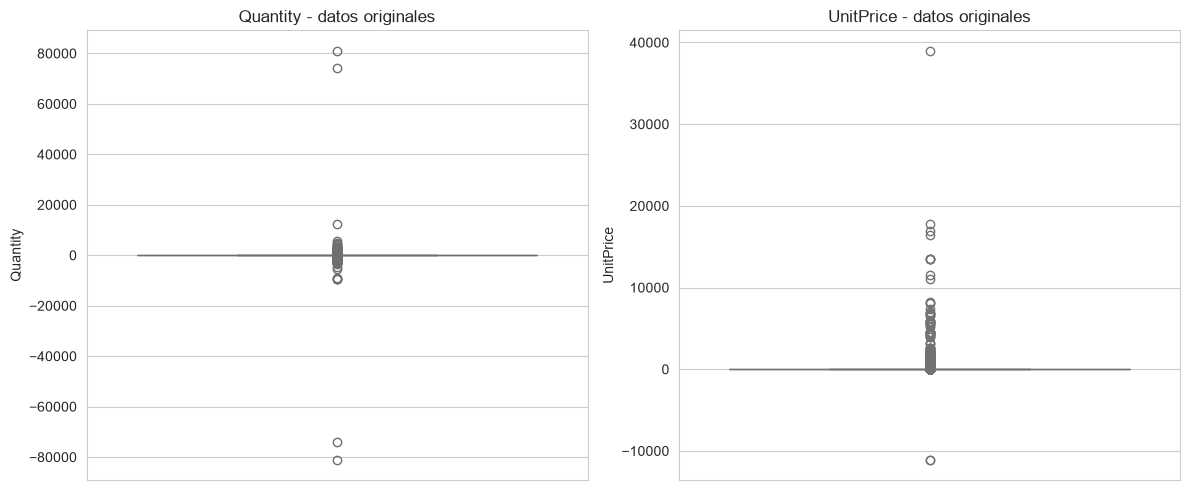

In [22]:
# Boxplot con todos los datos (incluye negativos y extremos)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df["Quantity"], ax=ax[0], color="skyblue")
ax[0].set_title("Quantity - datos originales")

sns.boxplot(y=df["UnitPrice"], ax=ax[1], color="lightgreen")
ax[1].set_title("UnitPrice - datos originales")

plt.tight_layout()
plt.show()

### Boxplot sin valores extremos

Repito el boxplot ocultando los outliers (showfliers=False) para poder ver cómo se distribuye la mayoría de los datos.

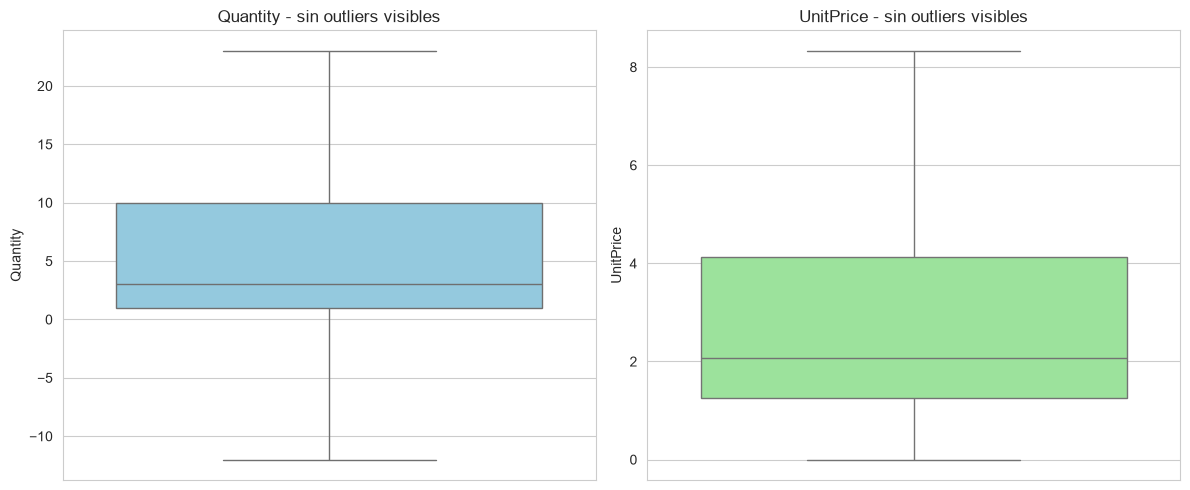

In [23]:
# Boxplot ocultando los outliers para ver la "caja"
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df["Quantity"], ax=ax[0], color="skyblue", showfliers=False)
ax[0].set_title("Quantity - sin outliers visibles")

sns.boxplot(y=df["UnitPrice"], ax=ax[1], color="lightgreen", showfliers=False)
ax[1].set_title("UnitPrice - sin outliers visibles")

plt.tight_layout()
plt.show()

### Registros por país (Top 10)

Muestro en un gráfico de barras los 10 países con más líneas de venta.

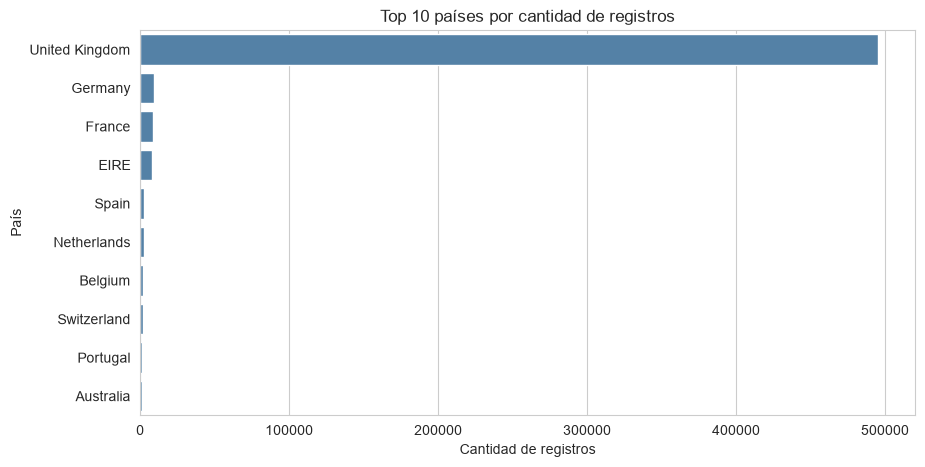

In [24]:
# Top 10 países por cantidad de registros
top_paises = df["Country"].value_counts().head(10)

sns.barplot(x=top_paises.values, y=top_paises.index, color="steelblue")
plt.title("Top 10 países por cantidad de registros")
plt.xlabel("Cantidad de registros")
plt.ylabel("País")
plt.show()

### Evolución de las ventas por mes

Calculo el importe de cada línea (Quantity × UnitPrice) y lo sumo por mes para ver cómo cambian las ventas en el tiempo.
Las variables se crean de forma temporal: todavía no modifico el dataset.

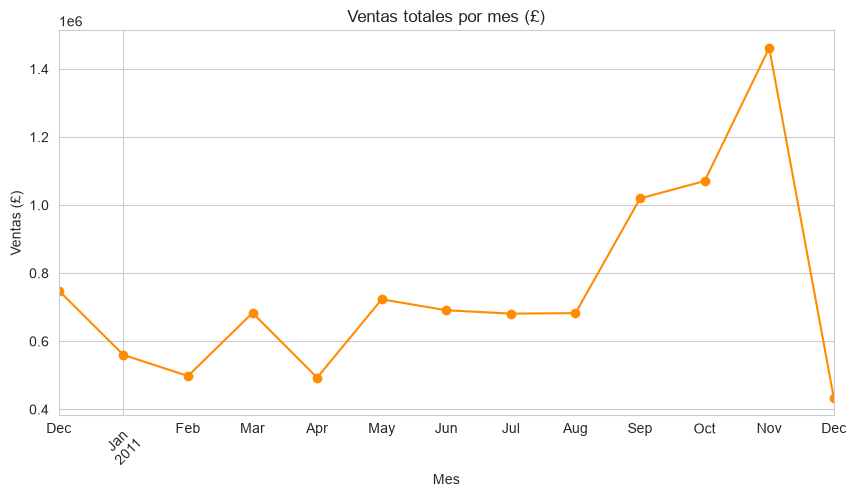

In [25]:
# Convertimos la fecha en una variable temporal (df no se modifica)
# El formato del archivo es mes/día/año hora:minuto  -> ej. 12/1/2010 8:26
fechas = pd.to_datetime(df["InvoiceDate"], format="%m/%d/%Y %H:%M")

# Importe de cada línea de venta
importe = df["Quantity"] * df["UnitPrice"]

# Sumamos el importe por mes
ventas_mes = importe.groupby(fechas.dt.to_period("M")).sum()

ventas_mes.plot(kind="line", marker="o", color="darkorange")
plt.title("Ventas totales por mes (£)")
plt.xlabel("Mes")
plt.ylabel("Ventas (£)")
plt.xticks(rotation=45)
plt.show()

### Top 10 productos más vendidos

Sumo la cantidad vendida por producto y muestro los 10 con más unidades.

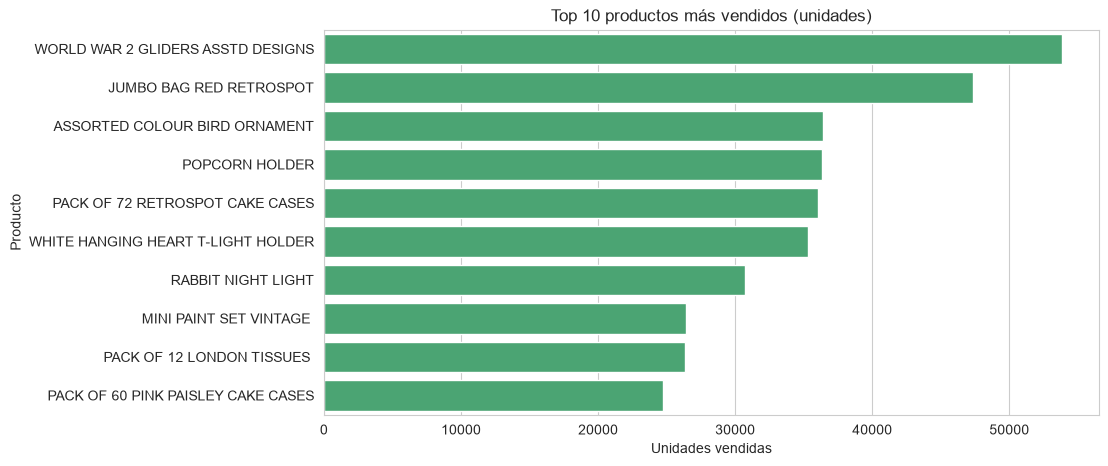

In [26]:
# Top 10 productos por unidades vendidas
top_productos = df.groupby("Description")["Quantity"].sum().sort_values(ascending=False).head(10)

sns.barplot(x=top_productos.values, y=top_productos.index, color="mediumseagreen")
plt.title("Top 10 productos más vendidos (unidades)")
plt.xlabel("Unidades vendidas")
plt.ylabel("Producto")
plt.show()